# Gradient descent on a 2D quadratic

Minimise $f(x) = \tfrac{1}{2} x^\top A x - b^\top x$ with positive definite
$A$. Three step sizes compared against the closed-form minimiser
$x^\star = A^{-1} b$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([1.0, -1.0])

x_star = np.linalg.solve(A, b)
print("Closed-form minimiser x* =", x_star)

# Eigenvalues give the step-size bounds: eta < 2 / lambda_max for stability.
eigvals = np.linalg.eigvalsh(A)
print(f"Eigenvalues of A: {eigvals}  (kappa = {eigvals.max()/eigvals.min():.2f})")
print(f"Max stable step size: eta < 2 / lambda_max = {2 / eigvals.max():.3f}")

Closed-form minimiser x* = [ 0.6 -0.8]
Eigenvalues of A: [1.38196601 3.61803399]  (kappa = 2.62)
Max stable step size: eta < 2 / lambda_max = 0.553


## 1. Objective, gradient, GD iterate

$$\nabla f(x) = A x - b, \qquad x_{k+1} = x_k - \eta \nabla f(x_k).$$

In [2]:
def f(x):
    return 0.5 * x @ A @ x - b @ x

def grad(x):
    return A @ x - b

def gd(x0, eta, n_iter=50):
    xs = [np.asarray(x0, dtype=float)]
    for _ in range(n_iter):
        xs.append(xs[-1] - eta * grad(xs[-1]))
    return np.array(xs)

## 2. Run with three step sizes

- $\eta = 0.1$: comfortably below the stability threshold, slow.
- $\eta = 0.4$: near-optimal for this spectrum.
- $\eta = 0.6$: close to the stability edge, zig-zag.

In [3]:
x0 = np.array([-1.5, 1.5])
trajs = {
    0.1: gd(x0, 0.1, 50),
    0.4: gd(x0, 0.4, 50),
    0.6: gd(x0, 0.6, 50),
}

for eta, traj in trajs.items():
    err = np.linalg.norm(traj[-1] - x_star)
    print(f"eta={eta}: final ||x - x*|| = {err:.3e}")

eta=0.1: final ||x - x*|| = 1.804e-03
eta=0.4: final ||x - x*|| = 0.000e+00
eta=0.6: final ||x - x*|| = 1.534e+03


## 3. Trajectories on the contour plot

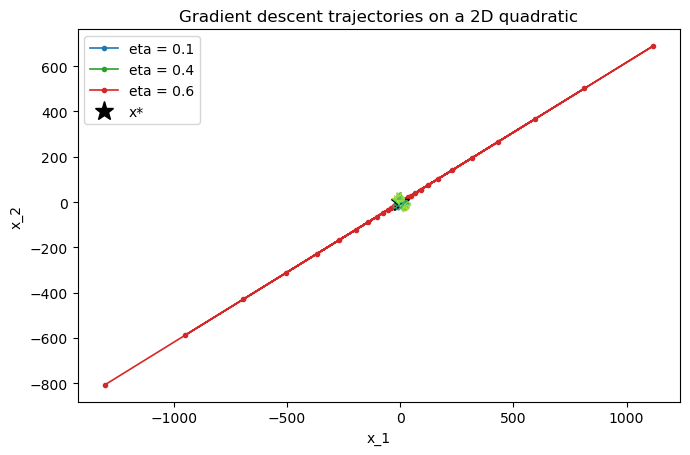

In [4]:
xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
zz = 0.5 * (A[0, 0] * xx**2 + 2 * A[0, 1] * xx * yy + A[1, 1] * yy**2) - (b[0] * xx + b[1] * yy)

fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contour(xx, yy, zz, levels=20, cmap="viridis")
ax.clabel(cs, inline=True, fontsize=7)

colors = {0.1: "tab:blue", 0.4: "tab:green", 0.6: "tab:red"}
for eta, traj in trajs.items():
    ax.plot(traj[:, 0], traj[:, 1], "o-", color=colors[eta],
            markersize=3, lw=1.2, label=f"eta = {eta}")

ax.plot(x_star[0], x_star[1], "k*", markersize=14, label="x*")
ax.set_xlabel("x_1")
ax.set_ylabel("x_2")
ax.set_title("Gradient descent trajectories on a 2D quadratic")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 4. Convergence of the error

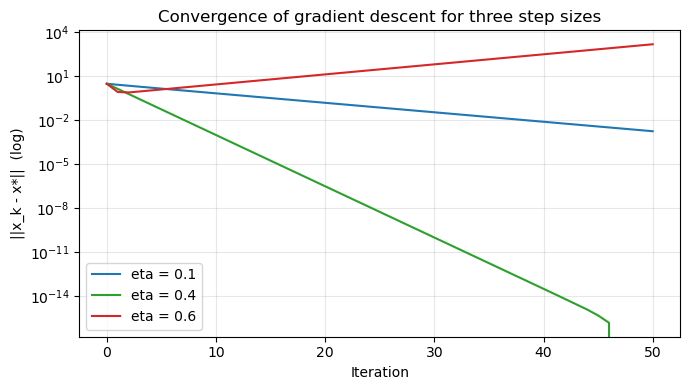

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for eta, traj in trajs.items():
    errs = np.linalg.norm(traj - x_star, axis=1)
    ax.semilogy(errs, label=f"eta = {eta}", color=colors[eta])
ax.set_xlabel("Iteration")
ax.set_ylabel("||x_k - x*||  (log)")
ax.set_title("Convergence of gradient descent for three step sizes")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. For this $A$, derive the **optimal** constant step size
   $\eta^\star = 2/(\lambda_{\min} + \lambda_{\max})$ and verify numerically
   that it gives the fastest contraction rate
   $(\kappa - 1)/(\kappa + 1)$.
2. Replace $A$ with a badly conditioned matrix (e.g. $\mathrm{diag}(1, 100)$)
   and plot the trajectory. Explain the zig-zag.
3. Add Polyak momentum ($x_{k+1} = x_k - \eta \nabla f(x_k) + \beta (x_k - x_{k-1})$)
   and compare against plain GD on the ill-conditioned case.